# A quick exercise with YOLO


0: 1024x1024 2 OBJ006s, 1 OBJ028, 18.2ms
Speed: 2.0ms preprocess, 18.2ms inference, 0.9ms postprocess per image at shape (1, 3, 1024, 1024)


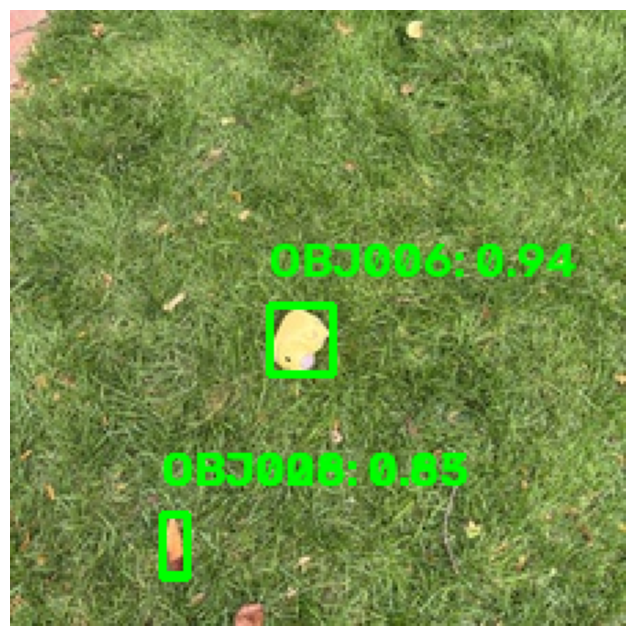

In [10]:

from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

# Load your trained model
model = YOLO("/home/varun/Documents/Deep learning/Project/best.pt")

# Load the test image
image_path = "/home/varun/Documents/Deep learning/DLAI/IE7615 Deep Learning for AI-20261010T195024Z-1-001/IE7615 Deep Learning for AI/images_OBJ006/OBJ006_065.jpg"
frame = cv2.imread(image_path)

if frame is None:
    print("Error: Could not load image.")
else:
    # Detect objects
    results = model(frame, conf=0.5, iou=0.7)

    # Draw bounding boxes and class labels
    for result in results:
        for box in result.boxes:
            x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
            confidence = float(box.conf[0])
            class_id = int(box.cls[0])
            class_name = model.names[class_id]

            # Green bounding box
            cv2.rectangle(
                frame, (x1, y1), (x2, y2), (0, 255, 0), 2
            )

            # Class name and confidence
            label = f"{class_name}: {confidence:.2f}"
            cv2.putText(
                frame, label, (x1, max(y1 - 10, 20)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2
            )

    # Convert BGR to RGB and display the image
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 8))
    plt.imshow(frame_rgb)
    plt.axis("off")
    plt.show()
